# DSC 210 -- Exam 2 Takehome -- Spring 2026

Name: Jacob Bauer

The dataset `heart_failure.csv` contains the medical records of 299 patients who had heart failure, collected during their follow-up period, where each patient profile has 13 clinical features [Davide Chicco, Giuseppe Jurman: *BMC Medical Informatics and Decision Making* 20, 16 (2020)].

The variables:
  - age: age of the patient
  - anaemia: decrease of red blood cells or hemoglobin
  - creatinine_phosphokinase: level of the CPK enzyme in the blood
  - diabetes: if the patient has diabetes
  - ejection_fraction: percentage of blood leaving the heart at each contraction
  - high_blood_pressure: if the patient has hypertension
  - platelets: platelets in the blood
  - serum_creatinine: level of serum creatinine in the blood
  - serum_sodium: level of serum sodium in the blood
  - sex: woman or man
  - smoking: if the patient smokes or not
  - time: follow-up period
  - **death_event: if the patient died during the follow-up period. (Target)**


Your task is to create a Decision Tree model that can predict whether a patient will survive or die during a follow-up period based on their clinical features. The following questions will prompt you through the analysis.

Begin by reading and inspecting the data.

In [1]:
import numpy as np
from matplotlib import pyplot as plt 
import seaborn as sns 
import pandas as pd

heart_df = pd.read_csv("heart_failure.csv")
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


1. Calculate and display a correlation matrix for the quantitative features. Are there any notable correlations between the features? Is this dataset a good candidate for principal component analysis? Explain your answers. **(5 points)**



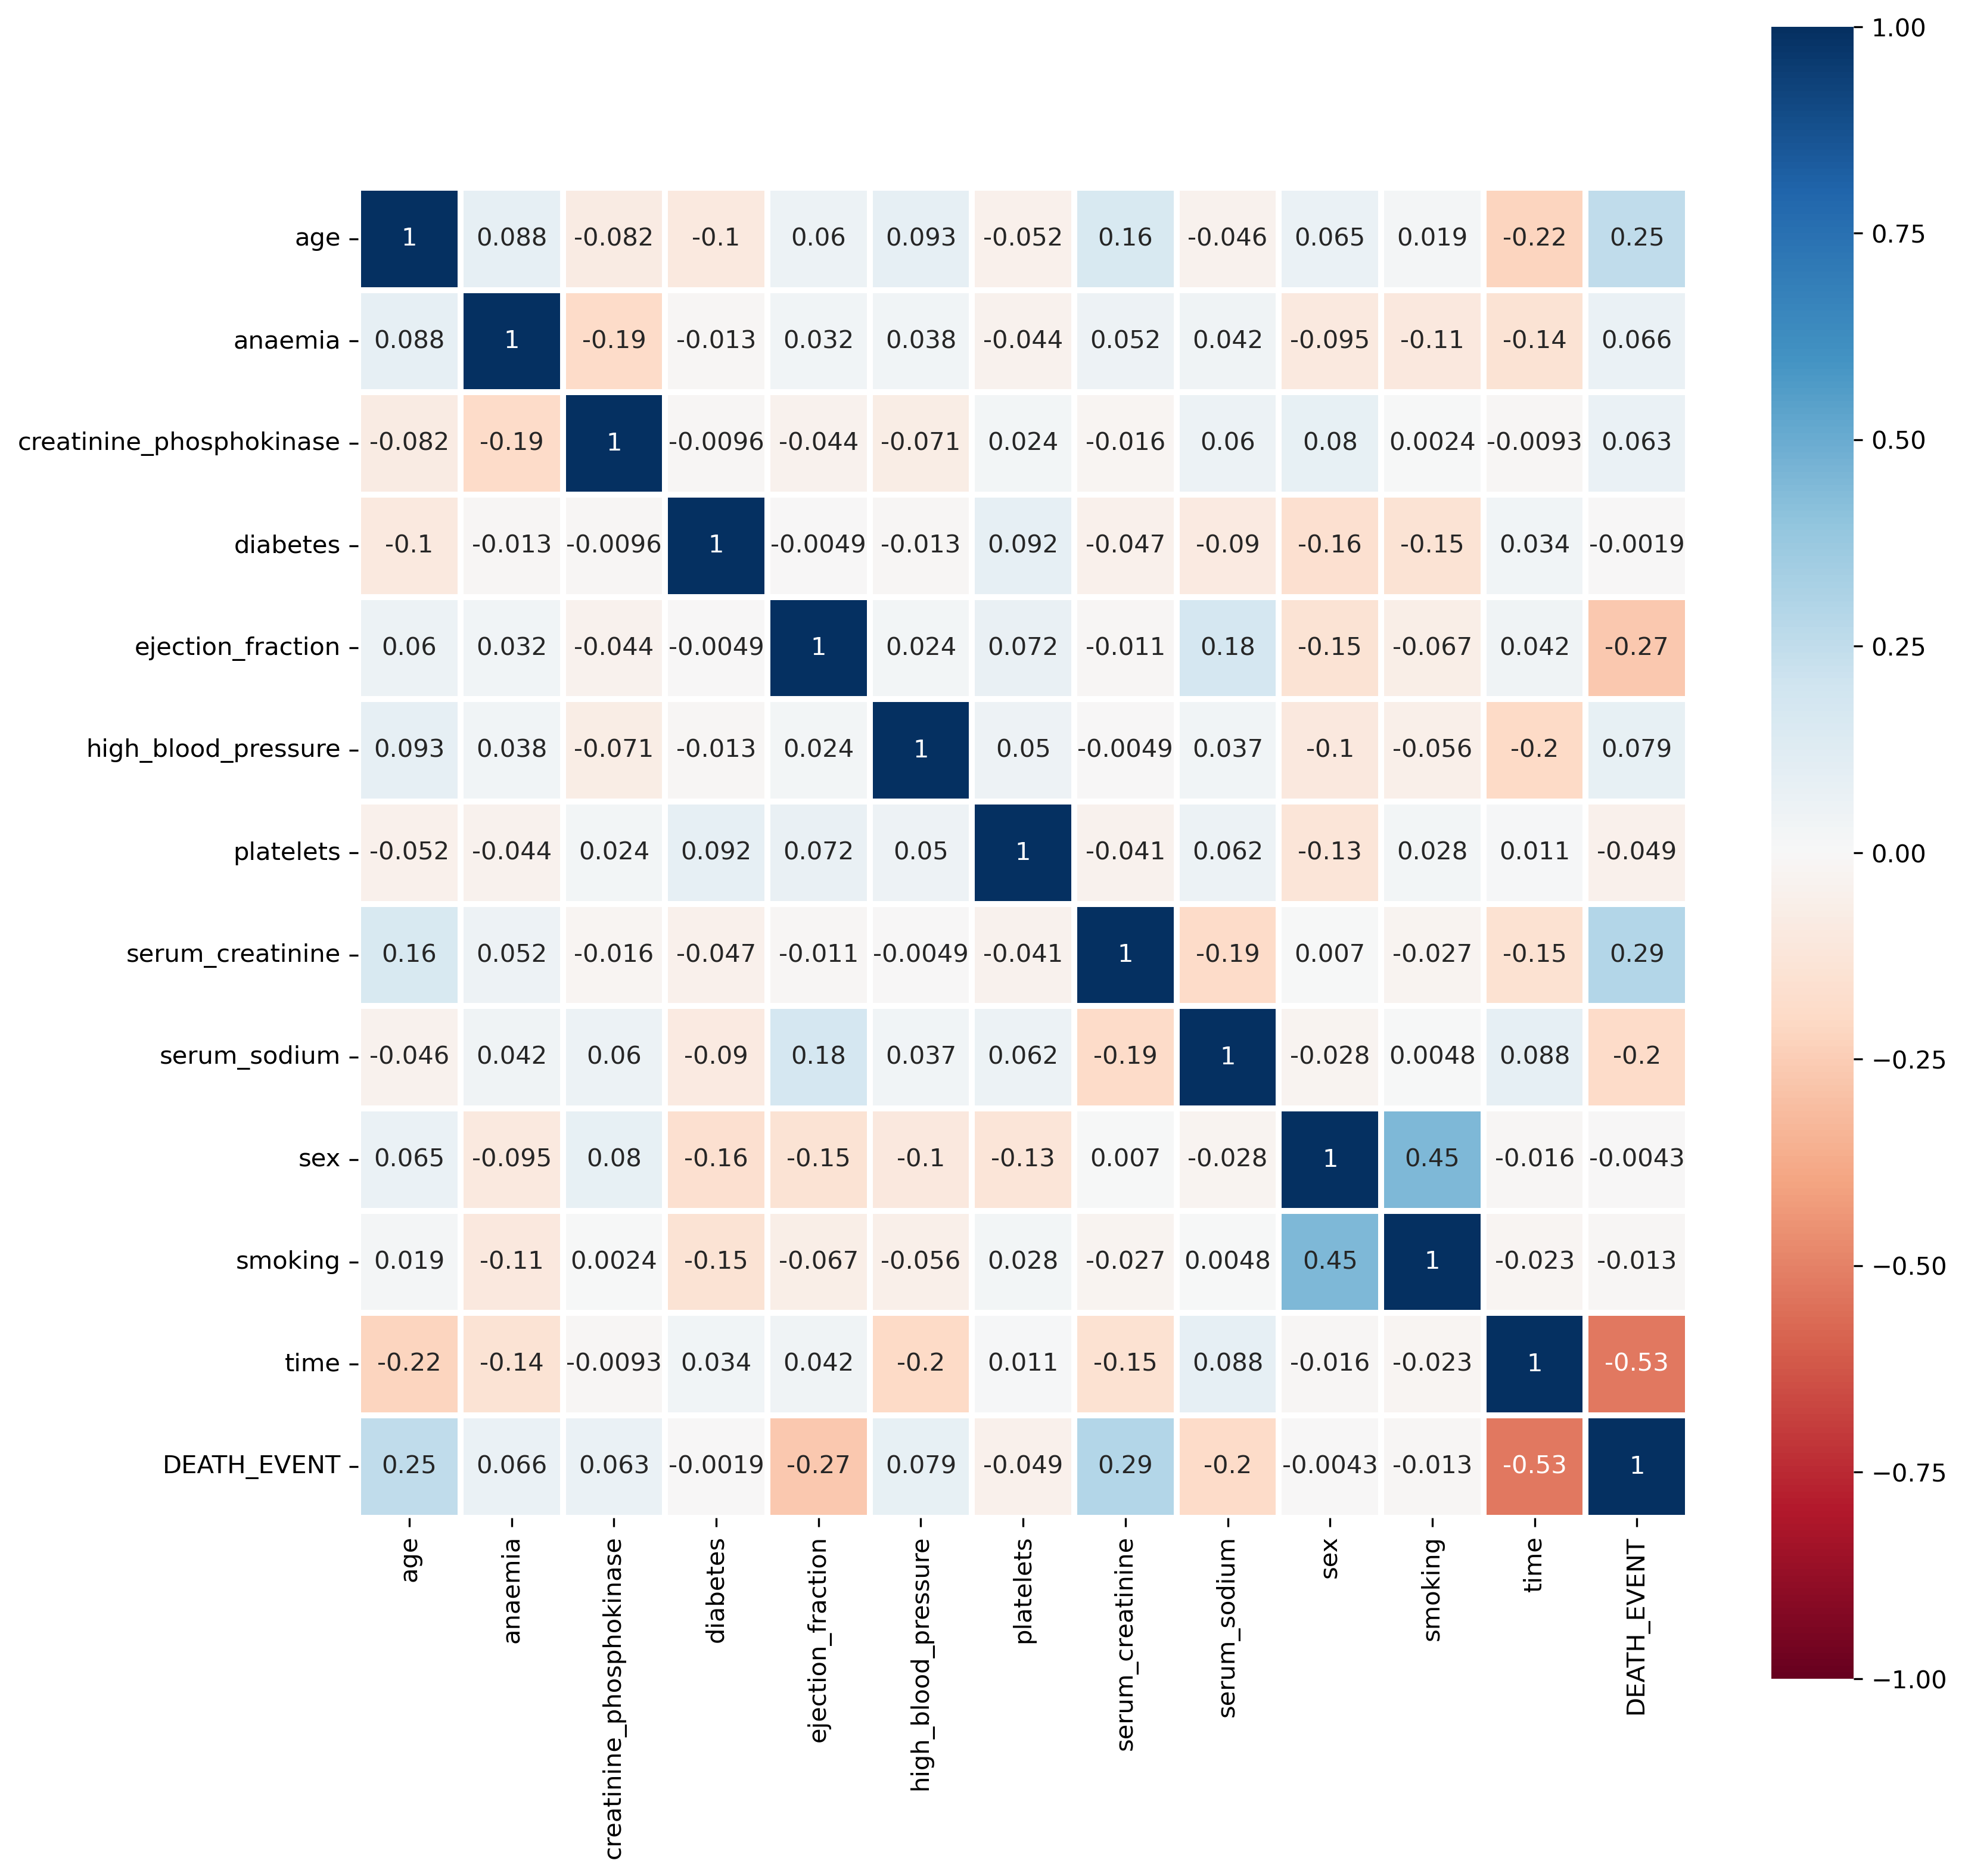

In [6]:
fig, ax = plt.subplots(figsize=(12, 12), dpi=300)

sns.heatmap(
    heart_df.corr(numeric_only=True),  
    vmin=-1, vmax=1,
    square=True, lw=2,
    annot=True, cmap="RdBu",
    ax = ax
)
plt.show() # Not good for PCA, no highly correlated variables

2. Create a visualization that displays the relationships between pairs of quantitative features in the dataset. Do any of the plots indicate any potential concerns for the analysis (i.e., skew, scale, outliers, correlation, etc.)? Explain. **(10 points)**

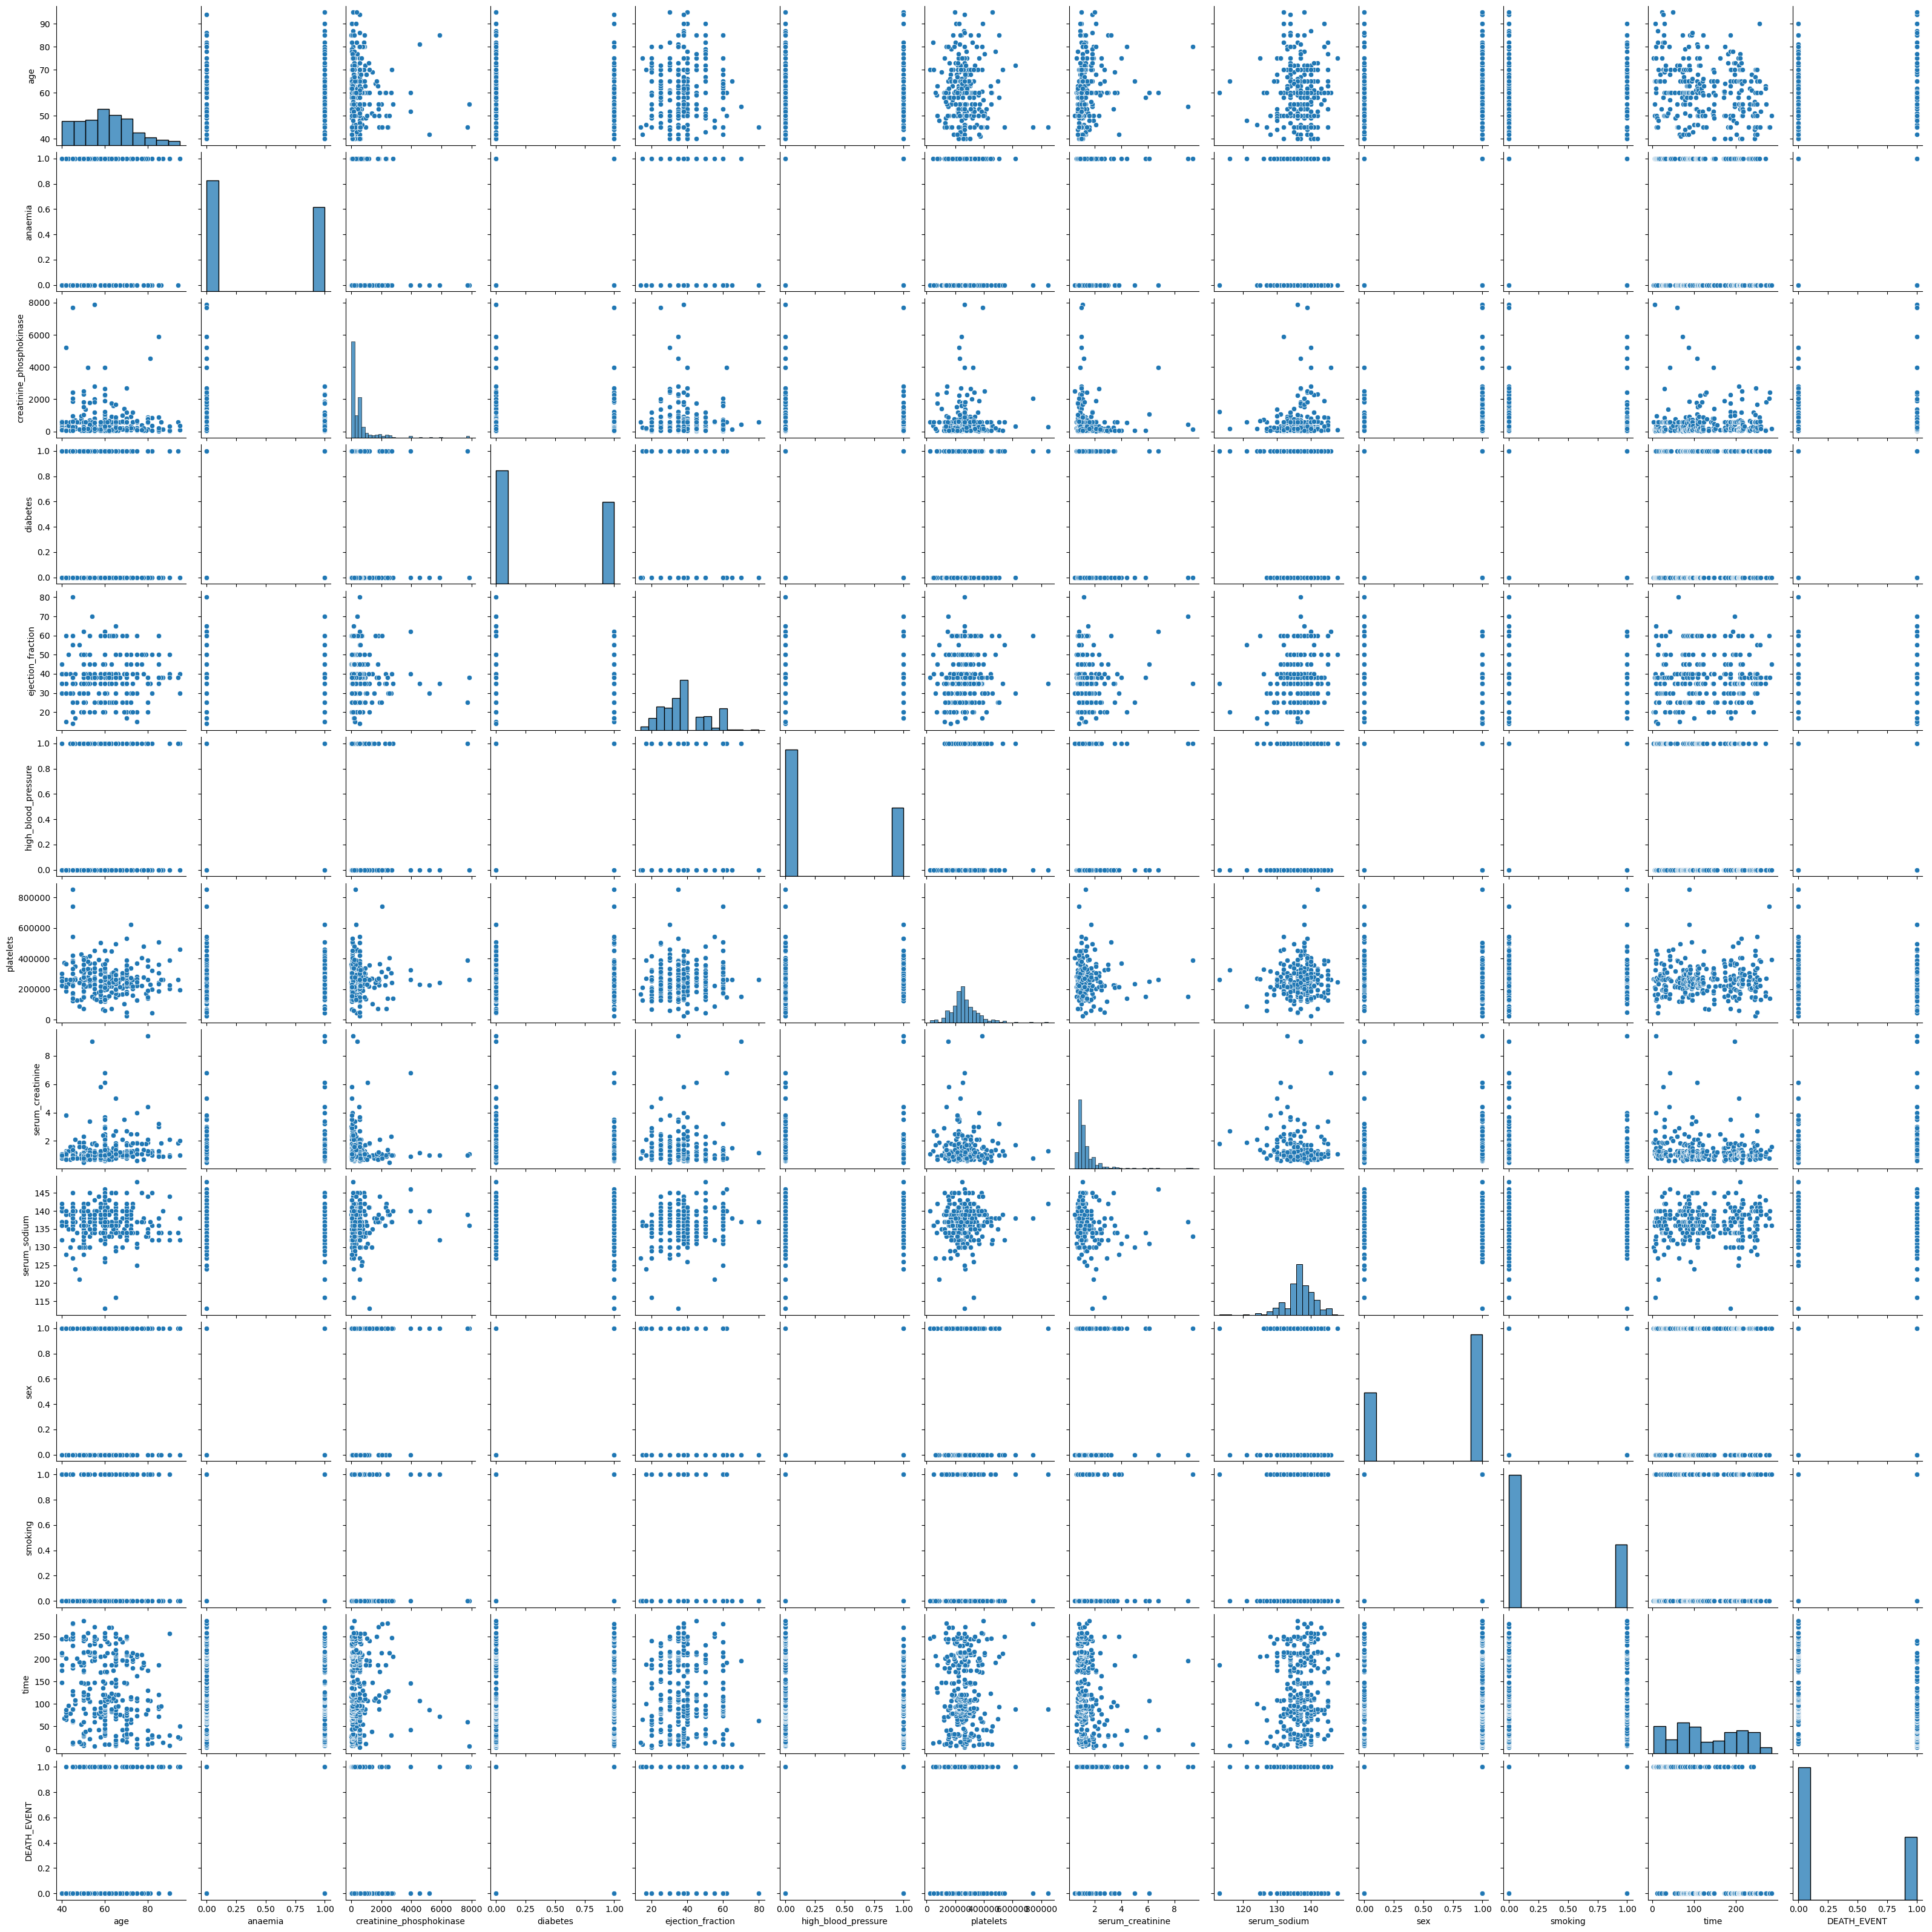

In [8]:
sns.pairplot(heart_df)

# It seems that a lot of this data is boolean type data where it is a yes or no answer. 
# It doesn't seem to me like there are any crazy outliers 
# serum_creatinine seems to be skewed left when looking at the pairplot 
# Nothing is very highly correlated 




3. Detect outliers, and justify your choice of algorithm. You can anticipate approximately 5% outliers in this data. Once complete, use the resulting information to remove the outliers from your dataset. How many observations were removed in this way? **(5 points)**

In [10]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest( # Used iso forest because of high dimensionality
    n_estimators = 100,
    contamination = 0.05,
    n_jobs = -1,
    random_state = 42,
    verbose = 0
)

iso_forest.fit(heart_df)

outlier_class = iso_forest.predict(heart_df)

num_outliers = (outlier_class == -1).sum()
print(f"Number of outliers: {num_outliers}")

heart_df_clean = heart_df[outlier_class == 1]


Number of outliers: 15


4. Prepare the data for modeling. This may include, and is not limited to, scaling, one-hot-encoding, and/or sample splitting. *Only perform steps that are necessary.* Explain your choices. **(10 points)**

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = heart_df_clean.drop("DEATH_EVENT", axis = 1)
Y = heart_df_clean["DEATH_EVENT"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, 
    test_size = 0.25,
    random_state = 42
)

# No need for standardizing the data for a decision tree
# No need to one hot encode for a decision tree
# Always need to split the data into training data and testing data

5. Fit a Decision Tree. **(10 points)**
  - Choose a reasonable tree depth, and justify your choice.
  - Display a heatmap of the resulting confusion matrix for predictions.
  - Calculate accuracy, precision, recall, and F1 score based on the confusion matrix.
  - Comment on the overall strength of the model. Which metric(s) is most important in this research scenario, and how does this model perform?
  - Display the decision tree.

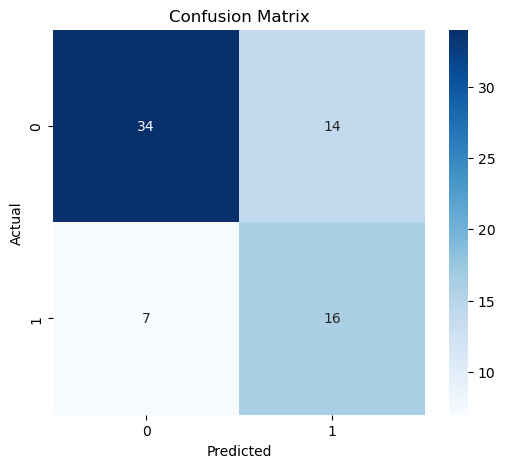

Accuracy: 0.704225352112676
Precision: 0.5333333333333333
Recall: 0.6956521739130435
F1 Score: 0.6037735849056604


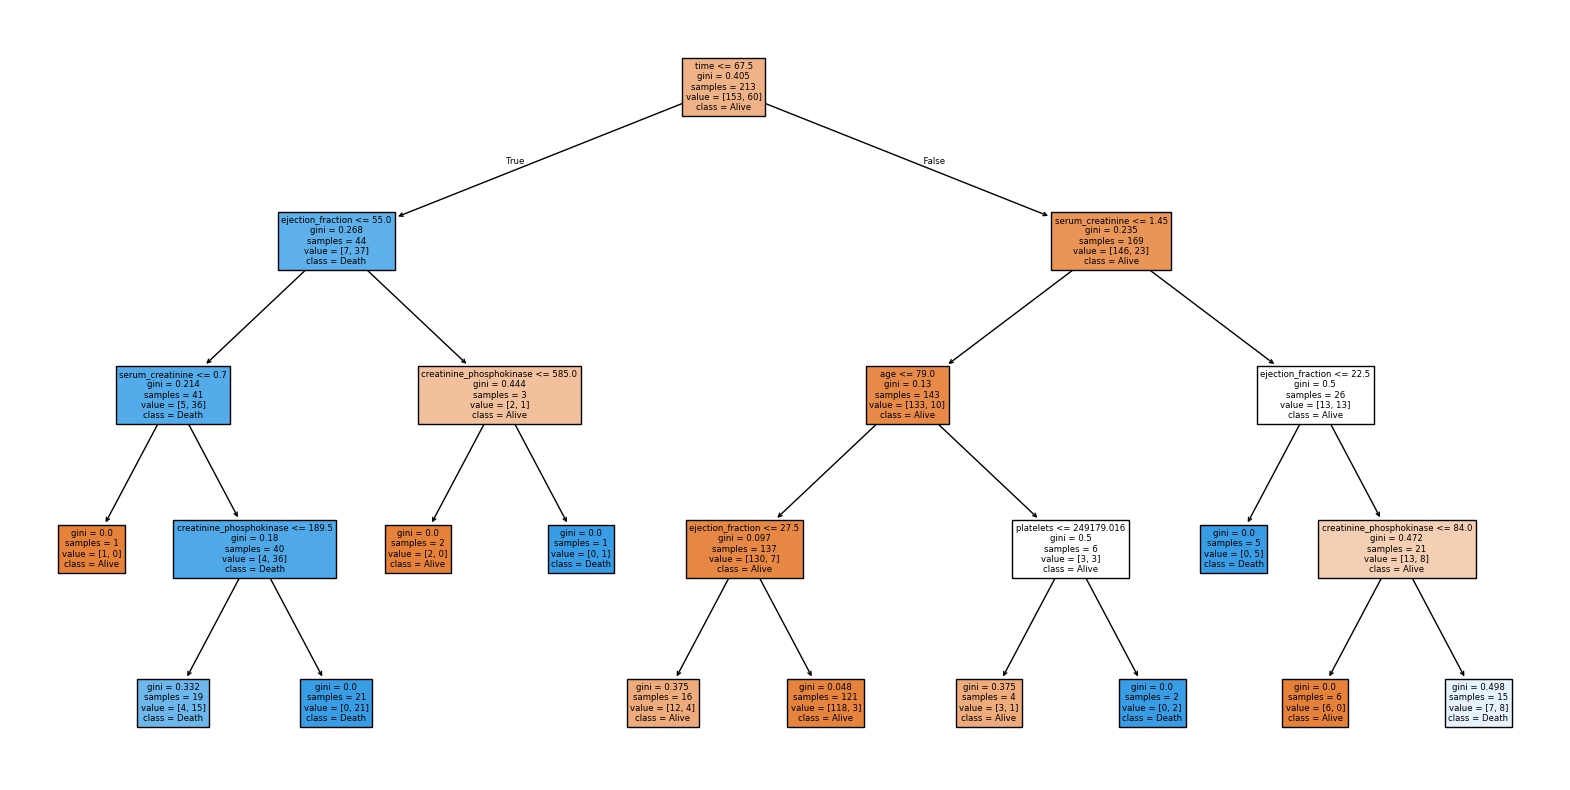

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import plot_tree
from sklearn.metrics import confusion_matrix

tree = DecisionTreeClassifier(
    max_depth=4, # Chose 4 decisions to try and keep the tree as simple as possible, this has a large effect on the accuracy score.
    random_state=42
)

tree.fit(X_train, Y_train)

Y_pred = tree.predict(X_test)

cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

plt.figure(figsize=(20,10))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["Alive", "Death"],
    filled=True
)
plt.show()


# Accuracy of this model was not great, even when I increased the depth to 10, we only had an accuracy of roughly 80%
# Most important metric: Recall, which is the ability to correctly identify which patients will die

6. Use a LLM AI (ChatGPT, Gemini, etc.) to create an additional data visualization that conveys the same (to some extent) information as the decision tree. The basis of this visualization is likely a scatterplot, but the details are up to you. Report the prompt you used, display the visualization, and explain the relationship between this visualization and the decision tree above. **(10 points)**

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


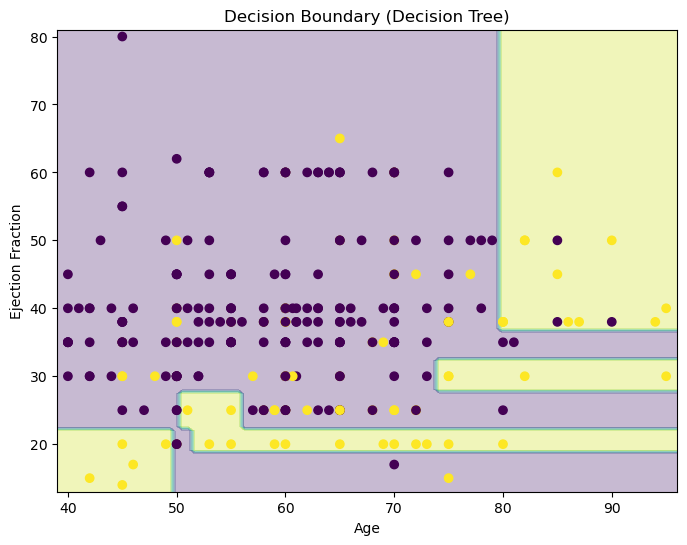

In [22]:
# Select two features
X_vis = heart_df_clean[["age", "ejection_fraction"]]
y_vis = heart_df_clean["DEATH_EVENT"]

# Train a tree on just these two features
from sklearn.tree import DecisionTreeClassifier
tree_vis = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_vis.fit(X_vis, y_vis)

# Create mesh grid
x_min, x_max = X_vis["age"].min() - 1, X_vis["age"].max() + 1
y_min, y_max = X_vis["ejection_fraction"].min() - 1, X_vis["ejection_fraction"].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 100),
    np.linspace(y_min, y_max, 100)
)

# Predict on grid
Z = tree_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3)

# Scatter points
plt.scatter(X_vis["age"], X_vis["ejection_fraction"], c=y_vis)

plt.xlabel("Age")
plt.ylabel("Ejection Fraction")
plt.title("Decision Boundary (Decision Tree)")
plt.show()

# Prompt: “Create a scatterplot using two important features from my dataset 
# (e.g., age and ejection_fraction), color points by the target variable (DEATH_EVENT), 
# and overlay the decision boundaries from a trained DecisionTreeClassifier.”

# This visualization represents the decision tree’s behavior in a two-dimensional space using age and ejection fraction. 
# The background regions show how the decision tree partitions the feature space into different prediction zones.
# Each rectangular region corresponds to a split made by the decision tree, 
# since decision trees create axis-aligned decision boundaries. This is why the boundaries appear as horizontal and vertical lines.



